## SET - A

In [2]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

In [4]:
SEED = 42
BATCH_SIZE = 64
LEARNING_RATE = 0.001
EPOCHS = 2
EPSILONS = [0.05, 0.10, 0.20, 0.30]
DEVICE = torch.device("cpu")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

torch.set_num_threads(2)

#### Loading Dataset

In [5]:
transform = transforms.ToTensor()  # Converts MNIST pixels to [0, 1]

train_dataset = datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)
test_dataset = datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

100%|██████████| 9.91M/9.91M [00:00<00:00, 20.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 493kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.59MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.01MB/s]


In [6]:
#Model
class CNN(nn.Module):
    """CNN with two convolutional layers and two fully connected layers."""

    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))  # 28x28 -> 14x14
        x = self.pool(self.relu(self.conv2(x)))  # 14x14 -> 7x7
        x = torch.flatten(x, start_dim=1)
        x = self.relu(self.fc1(x))
        return self.fc2(x)  # Raw logits for CrossEntropyLoss


model = CNN().to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

In [7]:
def train_clean_model(model, loader, optimizer, epochs):
    """Train the baseline model on clean images."""
    model.train()
    for epoch in range(epochs):
        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

        print(
            f"Baseline epoch {epoch + 1}/{epochs} | "
            f"loss: {running_loss / total:.4f} | "
            f"training accuracy: {100.0 * correct / total:.2f}%"
        )

In [8]:
def fgsm_attack(model, images, labels, epsilon):
    """
    Fast Gradient Sign Method:
    x_adv = clip(x + epsilon * sign(gradient_x loss), 0, 1)
    """
    model.eval()
    original_images = images.detach()
    perturbed_images = original_images.clone().detach().requires_grad_(True)

    outputs = model(perturbed_images)
    loss = criterion(outputs, labels)
    model.zero_grad()
    loss.backward()

    data_gradient = perturbed_images.grad.data
    adversarial_images = (
        perturbed_images + epsilon * data_gradient.sign()
    ).clamp(0.0, 1.0)

    return adversarial_images.detach()


In [9]:
def pgd_attack(model, images, labels, epsilon, iterations=10):
    """
    L-infinity Projected Gradient Descent.
    Uses a random start in [-epsilon, +epsilon], alpha=epsilon/4,
    and projects every update back into the epsilon-ball around x.
    """
    model.eval()
    original_images = images.detach()

    # Random start within the permitted L-infinity perturbation range.
    delta = torch.empty_like(original_images).uniform_(-epsilon, epsilon)
    adversarial_images = (original_images + delta).clamp(0.0, 1.0).detach()

    alpha = epsilon / 4.0

    for _ in range(iterations):
        adversarial_images.requires_grad_(True)
        outputs = model(adversarial_images)
        loss = criterion(outputs, labels)

        model.zero_grad()
        loss.backward()
        gradient = adversarial_images.grad.detach()

        with torch.no_grad():
            adversarial_images = adversarial_images + alpha * gradient.sign()

            # Project perturbation into the L-infinity epsilon-ball.
            delta = torch.clamp(
                adversarial_images - original_images,
                min=-epsilon,
                max=epsilon,
            )
            adversarial_images = (original_images + delta).clamp(0.0, 1.0)

        adversarial_images = adversarial_images.detach()

    return adversarial_images

In [10]:
#Evaluation
def evaluate_clean(model, loader):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            predictions = model(images).argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return 100.0 * correct / total


def evaluate_attack(model, loader, epsilon, attack_function):
    """Measure accuracy on adversarial examples generated batch by batch."""
    model.eval()
    correct = 0
    total = 0

    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        adversarial_images = attack_function(model, images, labels, epsilon)

        with torch.no_grad():
            predictions = model(adversarial_images).argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    return 100.0 * correct / total

### Task 1:


In [11]:
print("\nTASK 1: Training baseline CNN (2 epochs)...")
train_clean_model(model, train_loader, optimizer, EPOCHS)

baseline_clean_accuracy = evaluate_clean(model, test_loader)
print(f"\nBaseline clean test accuracy: {baseline_clean_accuracy:.2f}%")


TASK 1: Training baseline CNN (2 epochs)...
Baseline epoch 1/2 | loss: 0.1885 | training accuracy: 94.27%
Baseline epoch 2/2 | loss: 0.0501 | training accuracy: 98.49%

Baseline clean test accuracy: 98.68%


### Task2 and Task3:


In [13]:
print("\nTASKS 2 AND 3: Evaluating FGSM and PGD attacks...")
baseline_fgsm = {}
baseline_pgd = {}

for eps in EPSILONS:
    fgsm_acc = evaluate_attack(model, test_loader, eps, fgsm_attack)
    pgd_acc = evaluate_attack(
        model,
        test_loader,
        eps,
        lambda m, x, y, e: pgd_attack(m, x, y, e, iterations=10),
    )
    baseline_fgsm[eps] = fgsm_acc
    baseline_pgd[eps] = pgd_acc
    print(
        f"epsilon={eps:.2f} | FGSM accuracy={fgsm_acc:.2f}% | "
        f"PGD accuracy={pgd_acc:.2f}%"
    )

print("\nBaseline results")
print(f"{'EPSILON':>8} {'FGSM_ACC':>12} {'PGD_ACC':>12}")
print("-" * 34)
print(f"{0.00:8.2f} {baseline_clean_accuracy:11.2f}% "
      f"{baseline_clean_accuracy:11.2f}%")
for eps in EPSILONS:
    print(f"{eps:8.2f} {baseline_fgsm[eps]:11.2f}% "
          f"{baseline_pgd[eps]:11.2f}%")



TASKS 2 AND 3: Evaluating FGSM and PGD attacks...
epsilon=0.05 | FGSM accuracy=95.84% | PGD accuracy=95.39%
epsilon=0.10 | FGSM accuracy=88.81% | PGD accuracy=82.47%
epsilon=0.20 | FGSM accuracy=48.50% | PGD accuracy=6.83%
epsilon=0.30 | FGSM accuracy=10.49% | PGD accuracy=0.00%

Baseline results
 EPSILON     FGSM_ACC      PGD_ACC
----------------------------------
    0.00       98.68%       98.68%
    0.05       95.84%       95.39%
    0.10       88.81%       82.47%
    0.20       48.50%        6.83%
    0.30       10.49%        0.00%


### Task4


TASK 4: Creating clean vs adversarial image figure...
Image 5: mis-read 4 -> 9 (true label 4)


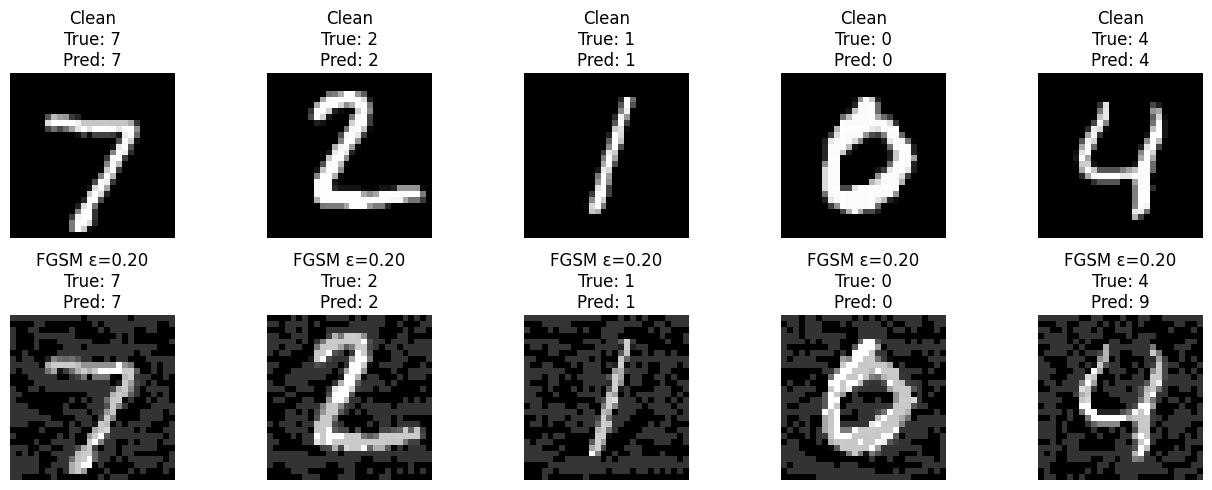

Saved: clean_vs_adversarial.png


In [14]:
def save_clean_vs_adversarial(model, dataset, epsilon=0.20, count=5):
    """Save five clean test images and their FGSM versions with predictions."""
    model.eval()
    images = torch.stack([dataset[i][0] for i in range(count)]).to(DEVICE)
    labels = torch.tensor([dataset[i][1] for i in range(count)]).to(DEVICE)

    with torch.no_grad():
        clean_predictions = model(images).argmax(dim=1)

    adversarial_images = fgsm_attack(model, images, labels, epsilon)

    with torch.no_grad():
        adversarial_predictions = model(adversarial_images).argmax(dim=1)

    fig, axes = plt.subplots(2, count, figsize=(13, 5))

    for i in range(count):
        axes[0, i].imshow(images[i].squeeze().cpu(), cmap="gray")
        axes[0, i].set_title(
            f"Clean\nTrue: {labels[i].item()}\nPred: {clean_predictions[i].item()}"
        )
        axes[0, i].axis("off")

        axes[1, i].imshow(adversarial_images[i].squeeze().cpu(), cmap="gray")
        axes[1, i].set_title(
            f"FGSM ε={epsilon:.2f}\nTrue: {labels[i].item()}\n"
            f"Pred: {adversarial_predictions[i].item()}"
        )
        axes[1, i].axis("off")

        if clean_predictions[i].item() != adversarial_predictions[i].item():
            print(
                f"Image {i + 1}: mis-read "
                f"{clean_predictions[i].item()} -> "
                f"{adversarial_predictions[i].item()} "
                f"(true label {labels[i].item()})"
            )

    axes[0, 0].set_ylabel("Clean", fontsize=12)
    axes[1, 0].set_ylabel("FGSM", fontsize=12)
    plt.tight_layout()
    plt.savefig("clean_vs_adversarial.png", dpi=200, bbox_inches="tight")
    plt.show()
    print("Saved: clean_vs_adversarial.png")


print("\nTASK 4: Creating clean vs adversarial image figure...")
save_clean_vs_adversarial(model, test_dataset, epsilon=0.20, count=5)

In [15]:
def adversarial_finetune(model, loader, epochs=2, epsilon=0.20):
    """
    Fine-tune on a 50:50 mix:
    half clean images and half FGSM images, with corresponding labels.
    Each source batch generates one clean/adversarial pair per example.
    """
    adv_optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for clean_images, labels in loader:
            clean_images = clean_images.to(DEVICE)
            labels = labels.to(DEVICE)

            # Generate adversarial examples using the current model.
            # The attack function handles gradients for the input.
            adversarial_images = fgsm_attack(
                model, clean_images, labels, epsilon
            )

            # 50:50 clean and adversarial training batch.
            mixed_images = torch.cat(
                [clean_images, adversarial_images], dim=0
            )
            mixed_labels = torch.cat([labels, labels], dim=0)

            model.train()
            adv_optimizer.zero_grad()
            outputs = model(mixed_images)
            loss = criterion(outputs, mixed_labels)
            loss.backward()
            adv_optimizer.step()

            running_loss += loss.item() * mixed_labels.size(0)
            correct += (outputs.argmax(dim=1) == mixed_labels).sum().item()
            total += mixed_labels.size(0)

        print(
            f"Adversarial-training epoch {epoch + 1}/{epochs} | "
            f"loss: {running_loss / total:.4f} | "
            f"mixed-batch accuracy: {100.0 * correct / total:.2f}%"
        )


print("\nTASK 5: Adversarial training (2 epochs, 50:50 clean/FGSM mix)...")
adversarial_finetune(model, train_loader, epochs=2, epsilon=0.20)

adv_clean_accuracy = evaluate_clean(model, test_loader)
adv_fgsm_accuracy = evaluate_attack(model, test_loader, 0.20, fgsm_attack)
adv_pgd_accuracy = evaluate_attack(
    model,
    test_loader,
    0.20,
    lambda m, x, y, e: pgd_attack(m, x, y, e, iterations=10),
)

print("\nBaseline vs adversarially-trained model")
print(f"{'MODEL':<25} {'CLEAN':>10} {'FGSM(0.20)':>14} {'PGD(0.20)':>12}")
print("-" * 65)
print(
    f"{'Baseline':<25} {baseline_clean_accuracy:9.2f}% "
    f"{baseline_fgsm[0.20]:13.2f}% {baseline_pgd[0.20]:11.2f}%"
)
print(
    f"{'Adversarially trained':<25} {adv_clean_accuracy:9.2f}% "
    f"{adv_fgsm_accuracy:13.2f}% {adv_pgd_accuracy:11.2f}%"
)

print("\nChanges after adversarial training")
print(f"Clean accuracy change: {adv_clean_accuracy - baseline_clean_accuracy:+.2f} "
      "percentage points")
print(f"FGSM robustness gain: {adv_fgsm_accuracy - baseline_fgsm[0.20]:+.2f} "
      "percentage points")
print(f"PGD robustness gain: {adv_pgd_accuracy - baseline_pgd[0.20]:+.2f} "
      "percentage points")


TASK 5: Adversarial training (2 epochs, 50:50 clean/FGSM mix)...
Adversarial-training epoch 1/2 | loss: 0.2496 | mixed-batch accuracy: 91.72%
Adversarial-training epoch 2/2 | loss: 0.1480 | mixed-batch accuracy: 95.13%

Baseline vs adversarially-trained model
MODEL                          CLEAN     FGSM(0.20)    PGD(0.20)
-----------------------------------------------------------------
Baseline                      98.68%         48.50%        6.83%
Adversarially trained         99.00%         92.62%       23.83%

Changes after adversarial training
Clean accuracy change: +0.32 percentage points
FGSM robustness gain: +44.12 percentage points
PGD robustness gain: +17.00 percentage points



TASK 6: Plotting baseline accuracy vs epsilon...


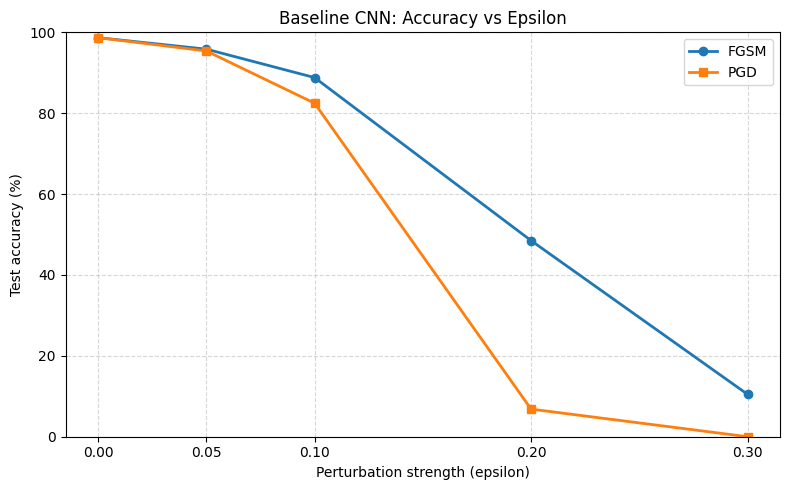

Saved: accuracy_vs_epsilon.png
Saved model: adversarially_trained_cnn.pth


In [16]:
print("\nTASK 6: Plotting baseline accuracy vs epsilon...")
x_values = [0.00] + EPSILONS
fgsm_values = [baseline_clean_accuracy] + [baseline_fgsm[e] for e in EPSILONS]
pgd_values = [baseline_clean_accuracy] + [baseline_pgd[e] for e in EPSILONS]

plt.figure(figsize=(8, 5))
plt.plot(x_values, fgsm_values, marker="o", linewidth=2, label="FGSM")
plt.plot(x_values, pgd_values, marker="s", linewidth=2, label="PGD")
plt.xlabel("Perturbation strength (epsilon)")
plt.ylabel("Test accuracy (%)")
plt.title("Baseline CNN: Accuracy vs Epsilon")
plt.xticks(x_values)
plt.ylim(0, 100)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.savefig("accuracy_vs_epsilon.png", dpi=200, bbox_inches="tight")
plt.show()
print("Saved: accuracy_vs_epsilon.png")


# Save the trained model weights for future use.
torch.save(model.state_dict(), "adversarially_trained_cnn.pth")
print("Saved model: adversarially_trained_cnn.pth")

In [ ]:


# ---------------- Task 6: Accuracy vs epsilon plot and summary -------------

